In [1]:
# Import libraries. You may or may not use all of these.
# !pip install -q git+https://github.com/tensorflow/docs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
  # %tensorflow_version only exists in Colab.
  %tensorflow_version 2.x
except Exception:
  pass
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

import tensorflow_docs as tfdocs
import tensorflow_docs.plots
import tensorflow_docs.modeling

I0000 00:00:1794305659.992630    5421 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794305659.993325    5421 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794305660.205906    5421 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794305661.353120    5421 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
# Import data
# !wget https://cdn.freecodecamp.org/project-data/health-costs/insurance.csv
dataset = pd.read_csv('insurance.csv')
dataset.tail()

,age,sex,bmi,children,smoker,region,expenses
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95
1337,61,female,29.1,0,yes,northwest,29141.36


In [ ]:
# Data Clearing and Encoding

# Encoding 
dataset["smoker"] = dataset["smoker"].map({"yes":0 , "no" :1})
dataset["sex"] = dataset["sex"].map({"female" : 0, "male":1})

# Create dummies 

dummies = pd.get_dummies(dataset["region"], dtype=int)
dataset = pd.concat([dataset,dummies], axis=1).drop(["region", "southwest"], axis= 1) # we drop the original column and also drop one of the 4 ones for redundency

# Splitting the dataset into 2 

train_dataset = dataset.sample(frac=0.8, random_state=1)

test_dataset = dataset.drop(train_dataset.index)

# Then we drop the "expenses" column from both 

train_labels = train_dataset.pop("expenses")

test_labels = test_dataset.pop("expenses")




KeyError: 'region'

In [ ]:

#! We need to normalize the inputs 

normalizer = tf.keras.layers.Normalization()

normalizer.adapt(np.array(train_dataset))




(1070, 8)


In [ ]:
# Create the model

#! It says to build a linear model so we only use Dense layers no Conv or maxpooling ones
model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(train_dataset.shape[1],)),
        normalizer,
        tf.keras.layers.Dense(64,activation="relu"),
        tf.keras.layers.Dense(64,activation="relu"),
        tf.keras.layers.Dense(1)]
)

# We also compile the model with the loss function and the optimizer and the metrics that we want to use 

model.compile(optimizer = tf.keras.optimizers.Adam(),
              loss = "mae",
              metrics = ["mae", "mse"])

# We then fit our data to the model 
model.fit(train_dataset,train_labels,
          epochs = 1000,
          validation_split=0.2,
          verbose = 1 )

9/9 - 0s - 3ms/step - loss: 1647.6023 - mae: 1647.6023 - mse: 25879260.0000
Testing set Mean Abs Error: 1647.60 expenses
You passed the challenge. Great job!
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


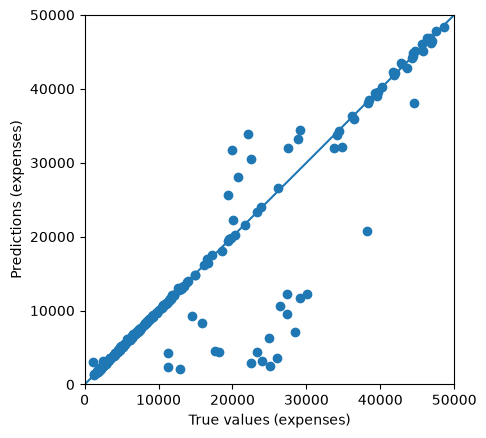

In [35]:
# RUN THIS CELL TO TEST YOUR MODEL. DO NOT MODIFY CONTENTS.
# Test model by checking how well the model generalizes using the test set.
loss, mae, mse = model.evaluate(test_dataset, test_labels, verbose=2)

print("Testing set Mean Abs Error: {:5.2f} expenses".format(mae))

if mae < 3500:
  print("You passed the challenge. Great job!")
else:
  print("The Mean Abs Error must be less than 3500. Keep trying.")

# Plot predictions.
test_predictions = model.predict(test_dataset).flatten()

a = plt.axes(aspect='equal')
plt.scatter(test_labels, test_predictions)
plt.xlabel('True values (expenses)')
plt.ylabel('Predictions (expenses)')
lims = [0, 50000]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims,lims)
